# Semi-supervised Multi-task BERT: recommendation status + rating band

Self-training (pseudo-labeling): train on the labeled subset, pseudo-label the unlabeled pool with the model's confident predictions, then retrain on labeled + pseudo-labeled data.

## 1. Imports

In [3]:
import os
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.amp import autocast, GradScaler

from transformers import (
    AutoModel,
    AutoTokenizer,
    get_linear_schedule_with_warmup
)

## 2. Environment (Colab)

In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
VRAM: 79.25 GB


In [6]:
torch.cuda.empty_cache()

print("Allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

print("Reserved:",
      round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

Allocated: 0.0 GB
Reserved: 0.0 GB


## 3. Configuration

In [7]:
# ---------------- Paths (Google Drive) ----------------
DATA_DIR = "/content/drive/MyDrive/project33/data"

TRAIN_PATH = f"{DATA_DIR}/train_df.csv"
VAL_PATH = f"{DATA_DIR}/validation.csv"
TEST_PATH = f"{DATA_DIR}/test.csv"

CHECKPOINT_DIR = "/content/drive/MyDrive/project33/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ---------------- Data / model ----------------
TEXT_COL = "body_clean"

TARGET_COLS = [
    "recommendation_status",
    "rating_band"
]

MODEL_NAME = "HooshvareLab/bert-fa-base-uncased"

# ---------------- Training parameters ----------------
BATCH_SIZE = 10
GRADIENT_ACCUMULATION_STEPS = 2

ENCODER_LR = 2e-5
HEAD_LR = 1e-4

WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

EPOCHS = 1
MAX_LENGTH = 96

WARMUP_RATIO = 0.05

NUM_WORKERS = 2
PIN_MEMORY = True

USE_AMP = torch.cuda.is_available()

# ---------------- Semi-supervised (self-training) parameters ----------------
SEED = 42

# Share of the labeled train rows whose labels are KEPT.
# The remaining rows (plus any train rows that had no label at all)
# become the unlabeled pool. Set to 1.0 to use all labels.
LABELED_FRACTION = 0.3

CONF_THRESHOLD = 0.90     # minimum softmax confidence to accept a pseudo-label
PSEUDO_ROUNDS = 2         # number of pseudo-label / retrain rounds
PSEUDO_EPOCHS = 1         # epochs per self-training round
MAX_UNLABELED = 20000     # max unlabeled rows scored per round (limits time)

IGNORE_INDEX = -100       # marks a missing / hidden label

# ---------------- Reproducibility ----------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------------- Device ----------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


## 4. Load and clean data

In [8]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)


print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (3756421, 6)
Validation: (751284, 6)
Test: (751285, 6)


In [9]:
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

# Validation / test need at least one label to be evaluated.
val_df = val_df.dropna(subset=TARGET_COLS, how="all")
test_df = test_df.dropna(subset=TARGET_COLS, how="all")

# Train rows without any label are NOT dropped here:
# they go to the unlabeled pool used by self-training.
print("Train (labeled + unlabeled):", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train (labeled + unlabeled): (3756421, 6)
Validation: (751284, 6)
Test: (751285, 6)


In [10]:
print(train_df.head(1))

         id  product_id             body recommendation_status rating_band  \
0  53672599      252058  به درد نمیخوره        not_recommended         Low   

       body_clean  
0  به درد نمیخوره  


In [11]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name, df["body_clean"].isna().sum().sum())
    print(name, df["rating_band"].isna().sum().sum())
    print(name, df["recommendation_status"].isna().sum().sum())

Train 363
Train 0
Train 0
Validation 81
Validation 0
Validation 0
Test 62
Test 0
Test 0


In [12]:
train_df = train_df.dropna(subset=[TEXT_COL]).reset_index(drop=True)
val_df = val_df.dropna(subset=[TEXT_COL]).reset_index(drop=True)
test_df = test_df.dropna(subset=[TEXT_COL]).reset_index(drop=True)

In [13]:
for col in TARGET_COLS:
    print(f"\n{col}")
    print(train_df[col].value_counts())
    print("Number of classes:", train_df[col].nunique())


recommendation_status
recommendation_status
recommended        2971671
no_idea             424050
not_recommended     360337
Name: count, dtype: int64
Number of classes: 3

rating_band
rating_band
High      2422594
Low        699790
Medium     633674
Name: count, dtype: int64
Number of classes: 3


## 5. Tokenizer

In [14]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded")
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

Tokenizer loaded
Vocabulary size: 100000


tokenizer test

In [15]:
sample_text = train_df["body_clean"].iloc[0]

encoded = tokenizer(
    sample_text,
    max_length=MAX_LENGTH,
    truncation=True,
    padding="max_length",
    return_tensors="pt"
)

print("Input IDs:", encoded["input_ids"].shape)
print("Attention Mask:", encoded["attention_mask"].shape)

Input IDs: torch.Size([1, 96])
Attention Mask: torch.Size([1, 96])


## 6. Label encoding (missing label = -100)

In [16]:
target_encoders = {}

for col in TARGET_COLS:

    encoder = LabelEncoder()
    encoder.fit(train_df[col].dropna())

    target_encoders[col] = encoder

    mapping = {
        label: idx
        for idx, label in enumerate(encoder.classes_)
    }

    for df in [train_df, val_df, test_df]:
        valid = df[col].notna()
        unknown = set(df.loc[valid, col].unique()) - set(mapping)

        if unknown:
            raise ValueError(f"Unknown labels in {col}: {unknown}")

        # Missing labels become IGNORE_INDEX (-100)
        df[col] = (
            df[col].map(mapping)
            .fillna(IGNORE_INDEX)
            .astype("int64")
        )

    print(f"{col}: {mapping}")

recommendation_status: {'no_idea': 0, 'not_recommended': 1, 'recommended': 2}
rating_band: {'High': 0, 'Low': 1, 'Medium': 2}


## 7. Labeled / unlabeled split

In [17]:
# Rows that really have at least one label
has_label = (train_df[TARGET_COLS] != IGNORE_INDEX).any(axis=1).to_numpy()
labeled_pos = np.flatnonzero(has_label)

# Keep labels only for LABELED_FRACTION of them
rng = np.random.RandomState(SEED)
n_keep = int(len(labeled_pos) * LABELED_FRACTION)
keep_pos = rng.choice(labeled_pos, size=n_keep, replace=False)

is_labeled = np.zeros(len(train_df), dtype=bool)
is_labeled[keep_pos] = True

labeled_df = train_df[is_labeled].reset_index(drop=True)
unlabeled_df = train_df[~is_labeled].reset_index(drop=True)

# Hidden true labels: used ONLY to measure pseudo-label quality, never for training
hidden_true_labels = unlabeled_df[TARGET_COLS].to_numpy().copy()

# Hide labels of the unlabeled pool
unlabeled_df[TARGET_COLS] = IGNORE_INDEX

print("Labeled rows:  ", len(labeled_df))
print("Unlabeled rows:", len(unlabeled_df))
print("Validation:    ", len(val_df))
print("Test:          ", len(test_df))

Labeled rows:   1126817
Unlabeled rows: 2629241
Validation:     751203
Test:           751223


## 8. Dataset and DataLoaders

In [18]:
class ReviewDataset(Dataset):

    def __init__(self, dataframe):
        self.texts = dataframe[TEXT_COL].astype(str).tolist()

        self.labels = dataframe[
            TARGET_COLS
        ].to_numpy(dtype="int64")

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        return {
            "text": self.texts[idx],
            "labels": torch.tensor(
                self.labels[idx],
                dtype=torch.long
            )
        }

In [19]:
def collate_fn(batch):

    texts = [item["text"] for item in batch]

    encoded = tokenizer(
        texts,
        max_length=MAX_LENGTH,
        truncation=True,
        padding="longest",
        return_tensors="pt"
    )

    labels = torch.stack([
        item["labels"] for item in batch
    ])

    return {
        "input_ids": encoded["input_ids"],
        "attention_mask": encoded["attention_mask"],
        "labels": labels
    }

In [20]:
def make_loader(dataframe, shuffle, batch_size=BATCH_SIZE):
    return DataLoader(
        ReviewDataset(dataframe),
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_fn,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )


train_loader = make_loader(labeled_df, shuffle=True)   # labeled data only
val_loader = make_loader(val_df, shuffle=False)
test_loader = make_loader(test_df, shuffle=False)

print("Labeled batches:", len(train_loader))

Labeled batches: 112682


## 9. Model

In [21]:
num_recommendation = len(target_encoders["recommendation_status"].classes_)
num_rating = len(target_encoders["rating_band"].classes_)

print("Recommendation classes:", num_recommendation)
print("Rating classes:", num_rating)

Recommendation classes: 3
Rating classes: 3


In [22]:
class MultiTaskBERT(nn.Module):

    def __init__(
        self,
        model_name,
        num_recommendation,
        num_rating,
        dropout=0.2
    ):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)

        hidden_size = self.encoder.config.hidden_size

        self.dropout = nn.Dropout(dropout)

        self.recommendation_head = nn.Linear(
            hidden_size,
            num_recommendation
        )

        self.rating_head = nn.Linear(
            hidden_size,
            num_rating
        )

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled_output = outputs.last_hidden_state[:, 0, :]

        pooled_output = self.dropout(pooled_output)

        recommendation_logits = self.recommendation_head(
            pooled_output
        )

        rating_logits = self.rating_head(
            pooled_output
        )

        return {
            "recommendation_logits": recommendation_logits,
            "rating_logits": rating_logits
        }

send to GPU

In [23]:
model = MultiTaskBERT(
    model_name=MODEL_NAME,
    num_recommendation=num_recommendation,
    num_rating=num_rating
).to(device)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Allocated VRAM:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

Device: cuda
GPU: NVIDIA A100-SXM4-80GB
Allocated VRAM: 0.61 GB


In [24]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)

model.eval()

with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

print("Recommendation:", outputs["recommendation_logits"].shape)
print("Rating:", outputs["rating_logits"].shape)

Recommendation: torch.Size([10, 3])
Rating: torch.Size([10, 3])


## 10. Loss and optimizer helpers

In [25]:
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)


def masked_ce(logits, targets):
    # If no sample in the batch has a label for this task, return 0
    # (CrossEntropyLoss would return NaN).
    if (targets != IGNORE_INDEX).any():
        return criterion(logits.float(), targets)
    return logits.sum() * 0.0


def calculate_loss(outputs, labels):

    loss_rec = masked_ce(
        outputs["recommendation_logits"],
        labels[:, 0]
    )

    loss_rating = masked_ce(
        outputs["rating_logits"],
        labels[:, 1]
    )

    total_loss = loss_rec + loss_rating

    return total_loss, loss_rec, loss_rating

In [26]:
batch = next(iter(train_loader))

input_ids = batch["input_ids"].to(device)
attention_mask = batch["attention_mask"].to(device)
labels = batch["labels"].to(device)

model.eval()

with torch.no_grad():

    with autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss, loss_rec, loss_rating = calculate_loss(
            outputs,
            labels
        )

print("Total Loss:", loss.item())
print("Recommendation Loss:", loss_rec.item())
print("Rating Loss:", loss_rating.item())

Total Loss: 2.3166143894195557
Recommendation Loss: 1.1581217050552368
Rating Loss: 1.1584926843643188


In [27]:
def build_optimizer_scheduler(model, loader, epochs):

    optimizer = AdamW(
        [
            {
                "params": model.encoder.parameters(),
                "lr": ENCODER_LR
            },
            {
                "params": model.recommendation_head.parameters(),
                "lr": HEAD_LR
            },
            {
                "params": model.rating_head.parameters(),
                "lr": HEAD_LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    num_training_steps = (
        math.ceil(len(loader) / GRADIENT_ACCUMULATION_STEPS) * epochs
    )

    num_warmup_steps = int(num_training_steps * WARMUP_RATIO)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=num_warmup_steps,
        num_training_steps=num_training_steps
    )

    print("Total optimizer steps:", num_training_steps)
    print("Warmup steps:", num_warmup_steps)

    return optimizer, scheduler

## 11. Evaluation, pseudo-labeling and training functions

In [28]:
def task_metrics(y_true, y_pred):
    # Only samples that really have a label for this task are scored
    mask = y_true != IGNORE_INDEX

    if mask.sum() == 0:
        return {k: float("nan") for k in ["accuracy", "precision", "recall", "f1"]}

    y_true = y_true[mask]
    y_pred = y_pred[mask]

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


def evaluate_model(model, dataloader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_rec_preds = []
    all_rating_preds = []

    with torch.no_grad():

        for batch in tqdm(dataloader, desc="Evaluating"):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            with autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

                loss, loss_rec, loss_rating = calculate_loss(
                    outputs,
                    labels
                )

            batch_size = input_ids.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_labels.append(labels.cpu().numpy())

            all_rec_preds.append(
                outputs["recommendation_logits"].argmax(dim=1).cpu().numpy()
            )
            all_rating_preds.append(
                outputs["rating_logits"].argmax(dim=1).cpu().numpy()
            )

    y_true = np.concatenate(all_labels)

    return {
        "loss": total_loss / total_samples,
        "recommendation": task_metrics(
            y_true[:, 0], np.concatenate(all_rec_preds)
        ),
        "rating": task_metrics(
            y_true[:, 1], np.concatenate(all_rating_preds)
        )
    }

In [29]:
@torch.no_grad()
def predict_probs(model, dataframe):

    loader = make_loader(
        dataframe,
        shuffle=False,
        batch_size=BATCH_SIZE * 2
    )

    model.eval()

    rec_probs, rating_probs = [], []

    for batch in tqdm(loader, desc="Pseudo-labeling"):

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        with autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        rec_probs.append(
            torch.softmax(outputs["recommendation_logits"].float(), dim=1).cpu()
        )
        rating_probs.append(
            torch.softmax(outputs["rating_logits"].float(), dim=1).cpu()
        )

    return torch.cat(rec_probs), torch.cat(rating_probs)


def make_pseudo_labels(model, pool_df, round_id):

    # Score only a random subset of the pool (limits time per round)
    if len(pool_df) > MAX_UNLABELED:
        pool_df = pool_df.sample(MAX_UNLABELED, random_state=SEED + round_id)

    rec_p, rating_p = predict_probs(model, pool_df)

    rec_conf, rec_pred = rec_p.max(dim=1)
    rating_conf, rating_pred = rating_p.max(dim=1)

    rec_keep = (rec_conf >= CONF_THRESHOLD).numpy()
    rating_keep = (rating_conf >= CONF_THRESHOLD).numpy()

    pseudo_df = pool_df.copy()

    # Low-confidence tasks stay at IGNORE_INDEX and are skipped by the loss
    pseudo_df["recommendation_status"] = np.where(
        rec_keep, rec_pred.numpy(), IGNORE_INDEX
    )
    pseudo_df["rating_band"] = np.where(
        rating_keep, rating_pred.numpy(), IGNORE_INDEX
    )

    # Diagnostics: compare with the hidden true labels (where they exist)
    true_labels = hidden_true_labels[pool_df.index.to_numpy()]

    for name, keep, pred, col in [
        ("recommendation", rec_keep, rec_pred.numpy(), 0),
        ("rating", rating_keep, rating_pred.numpy(), 1)
    ]:
        known = keep & (true_labels[:, col] != IGNORE_INDEX)
        acc = (
            (pred[known] == true_labels[known, col]).mean()
            if known.any() else float("nan")
        )
        print(
            f"{name}: accepted {keep.sum()}/{len(pool_df)} pseudo-labels, "
            f"accuracy vs hidden truth: {acc:.4f}"
        )

    return pseudo_df[rec_keep | rating_keep].reset_index(drop=True)

In [30]:
best = {"score": -1.0}
history = []


def run_stage(model, loader, epochs, stage_name):

    optimizer, scheduler = build_optimizer_scheduler(model, loader, epochs)
    scaler = GradScaler("cuda", enabled=USE_AMP)

    total_batches = len(loader)

    for epoch in range(epochs):

        print("\n" + "=" * 60)
        print(f"{stage_name} | epoch {epoch + 1}/{epochs}")
        print("=" * 60)

        model.train()
        optimizer.zero_grad(set_to_none=True)

        total_loss = 0.0
        total_samples = 0

        progress = tqdm(
            enumerate(loader),
            total=total_batches,
            desc="Training"
        )

        for step, batch in progress:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            batch_size = input_ids.size(0)

            # Correct accumulation for the final incomplete group
            group_start = (step // GRADIENT_ACCUMULATION_STEPS) * GRADIENT_ACCUMULATION_STEPS
            group_size = min(
                GRADIENT_ACCUMULATION_STEPS,
                total_batches - group_start
            )

            with autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask
                )

                loss, loss_rec, loss_rating = calculate_loss(
                    outputs,
                    labels
                )

                scaled_loss = loss / group_size

            scaler.scale(scaled_loss).backward()

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            should_update = (
                (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0
                or step + 1 == total_batches
            )

            if should_update:

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    MAX_GRAD_NORM
                )

                scaler.step(optimizer)
                scaler.update()
                scheduler.step()

                optimizer.zero_grad(set_to_none=True)

            progress.set_postfix({
                "loss": f"{loss.item():.4f}",
                "lr": f"{scheduler.get_last_lr()[0]:.2e}"
            })

        train_loss = total_loss / total_samples

        # ----- Validation -----
        val_results = evaluate_model(model, val_loader)

        rec = val_results["recommendation"]
        rating = val_results["rating"]

        current_score = float(np.nanmean([rec["f1"], rating["f1"]]))

        print(f"\nTrain Loss: {train_loss:.4f}")
        print(f"Validation Loss: {val_results['loss']:.4f}")

        print("\nRecommendation:")
        print(f"Accuracy:  {rec['accuracy']:.4f}")
        print(f"F1:        {rec['f1']:.4f}")

        print("\nRating:")
        print(f"Accuracy:  {rating['accuracy']:.4f}")
        print(f"F1:        {rating['f1']:.4f}")

        print(f"\nCombined Macro F1: {current_score:.4f}")

        history.append({
            "stage": stage_name,
            "epoch": epoch + 1,
            "train_samples": total_samples,
            "train_loss": train_loss,
            "val_loss": val_results["loss"],
            "recommendation_f1": rec["f1"],
            "rating_f1": rating["f1"],
            "combined_f1": current_score
        })

        # ----- Save best model across ALL stages -----
        if current_score > best["score"]:

            best["score"] = current_score

            torch.save(
                {
                    "stage": stage_name,
                    "epoch": epoch + 1,
                    "model_state_dict": model.state_dict(),
                    "best_score": best["score"],
                    "target_classes": {
                        col: target_encoders[col].classes_.tolist()
                        for col in TARGET_COLS
                    },
                    "model_name": MODEL_NAME,
                    "max_length": MAX_LENGTH
                },
                os.path.join(CHECKPOINT_DIR, "best_multitask_bert.pth")
            )

            print("\nBest model checkpoint saved!")

        print("=" * 60)

## 12. Train: supervised baseline, then self-training

In [31]:
# Stage 0: supervised training on the labeled subset only
run_stage(model, train_loader, EPOCHS, "supervised (labeled only)")

# Self-training rounds: pseudo-label -> merge with labeled data -> retrain
for round_id in range(1, PSEUDO_ROUNDS + 1):

    print("\n" + "#" * 60)
    print(f"Self-training round {round_id}/{PSEUDO_ROUNDS}")
    print("#" * 60)

    pseudo_df = make_pseudo_labels(model, unlabeled_df, round_id)

    if len(pseudo_df) == 0:
        print("No confident pseudo-labels found. Lower CONF_THRESHOLD. Stopping.")
        break

    combined_df = pd.concat(
        [labeled_df, pseudo_df],
        ignore_index=True
    )

    print(
        f"Training on {len(labeled_df)} labeled + "
        f"{len(pseudo_df)} pseudo-labeled rows"
    )

    combined_loader = make_loader(combined_df, shuffle=True)

    run_stage(
        model,
        combined_loader,
        PSEUDO_EPOCHS,
        f"self-training round {round_id}"
    )

Total optimizer steps: 56341
Warmup steps: 2817

supervised (labeled only) | epoch 1/1


Training:   0%|          | 0/112682 [00:00<?, ?it/s]

/tmp/ipykernel_631/2661520350.py:83: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Evaluating:   0%|          | 0/75121 [00:00<?, ?it/s]


Train Loss: 1.0395
Validation Loss: 0.9958

Recommendation:
Accuracy:  0.8756
F1:        0.7003

Rating:
Accuracy:  0.7428
F1:        0.5864

Combined Macro F1: 0.6434

Best model checkpoint saved!

############################################################
Self-training round 1/2
############################################################


Pseudo-labeling:   0%|          | 0/1000 [00:00<?, ?it/s]

... (5 outputs left out)

recommendation: accepted 14329/20000 pseudo-labels, accuracy vs hidden truth: 0.9692
rating: accepted 3063/20000 pseudo-labels, accuracy vs hidden truth: 0.9109
Training on 1126817 labeled + 14347 pseudo-labeled rows
Total optimizer steps: 57059
Warmup steps: 2852

self-training round 2 | epoch 1/1


Training:   0%|          | 0/114117 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/75121 [00:00<?, ?it/s]


Train Loss: 0.9699
Validation Loss: 1.0010

Recommendation:
Accuracy:  0.8756
F1:        0.7068

Rating:
Accuracy:  0.7429
F1:        0.5908

Combined Macro F1: 0.6488

Best model checkpoint saved!


In [32]:
history_df = pd.DataFrame(history)

history_path = os.path.join(
    CHECKPOINT_DIR,
    "training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

display(history_df)

,stage,epoch,train_samples,train_loss,val_loss,recommendation_f1,rating_f1,combined_f1
0,supervised (labeled only),1,1126817,1.039462,0.995816,0.700346,0.586405,0.643375
1,self-training round 1,1,1141008,0.992179,0.994893,0.706751,0.589748,0.648249
2,self-training round 2,1,1141164,0.969949,1.000994,0.706768,0.590789,0.648779


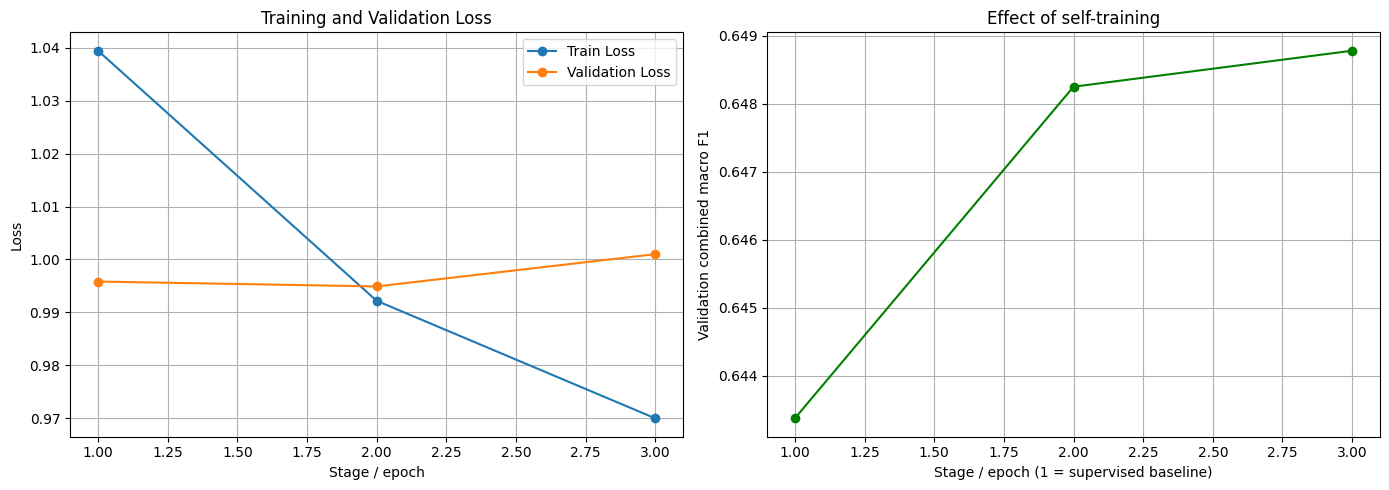

In [33]:
steps = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(steps, history_df["train_loss"], marker="o", label="Train Loss")
axes[0].plot(steps, history_df["val_loss"], marker="o", label="Validation Loss")
axes[0].set_xlabel("Stage / epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()
axes[0].grid()

axes[1].plot(steps, history_df["combined_f1"], marker="o", color="green")
axes[1].set_xlabel("Stage / epoch (1 = supervised baseline)")
axes[1].set_ylabel("Validation combined macro F1")
axes[1].set_title("Effect of self-training")
axes[1].grid()

plt.tight_layout()
plt.show()

## 13. Test evaluation and save

In [34]:
checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_multitask_bert.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)
model.eval()

print("Best stage:", checkpoint["stage"])
print("Best epoch:", checkpoint["epoch"])
print("Best Validation F1:", checkpoint["best_score"])

Best stage: self-training round 2
Best epoch: 1
Best Validation F1: 0.6487785805953876


In [35]:
test_results = evaluate_model(
    model,
    test_loader
)

print("\nFINAL TEST RESULTS")
print("=" * 50)

print("\nRecommendation Status")

for metric, value in test_results["recommendation"].items():
    print(f"{metric}: {value:.4f}")

print("\nRating Band")

for metric, value in test_results["rating"].items():
    print(f"{metric}: {value:.4f}")

print("\nTest Loss:", round(test_results["loss"], 4))

Evaluating:   0%|          | 0/75123 [00:00<?, ?it/s]


FINAL TEST RESULTS

Recommendation Status
accuracy: 0.8752
precision: 0.7262
recall: 0.6945
f1: 0.7066

Rating Band
accuracy: 0.7427
precision: 0.6712
recall: 0.5596
f1: 0.5904

Test Loss: 1.0027


In [36]:
SAVE_DIR = "/content/drive/MyDrive/project33/trained_model"

os.makedirs(SAVE_DIR, exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "model_name": MODEL_NAME,
    "num_recommendation": num_recommendation,
    "num_rating": num_rating,
    "target_classes": {
        col: target_encoders[col].classes_.tolist()
        for col in TARGET_COLS
    },
    "max_length": MAX_LENGTH,
    "labeled_fraction": LABELED_FRACTION,
    "conf_threshold": CONF_THRESHOLD,
    "pseudo_rounds": PSEUDO_ROUNDS,
}, os.path.join(SAVE_DIR, "model.pth"))

print("Model saved successfully!")

Model saved successfully!
